In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid', palette='Set2')
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.2f}'.format)

df_raw = sns.load_dataset('titanic')
print('Dataset carregado:', df_raw.shape)

Dataset carregado: (891, 15)


## 1. Análise Exploratória de Dados (EDA)
### 1.1 Estrutura dos dados

In [2]:
df_raw.info()
print()
df_raw.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB



,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.00,1,0,7.25,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.00,1,0,71.28,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.00,0,0,7.92,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.00,1,0,53.10,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.00,0,0,8.05,S,Third,man,True,NaN,Southampton,no,True


In [3]:
estrutura = pd.DataFrame({
    'tipo': df_raw.dtypes.astype(str),
    'valores_nulos': df_raw.isna().sum(),
    '%_nulos': (df_raw.isna().mean() * 100).round(1),
    'valores_unicos': df_raw.nunique()
})
estrutura

,tipo,valores_nulos,%_nulos,valores_unicos
survived,int64,0,0.00,2
pclass,int64,0,0.00,3
sex,object,0,0.00,2
age,float64,177,19.90,88
sibsp,int64,0,0.00,7
parch,int64,0,0.00,7
fare,float64,0,0.00,248
embarked,object,2,0.20,3
class,category,0,0.00,3
who,object,0,0.00,3


### 1.2 Medidas descritivas (variáveis numéricas)

In [4]:
num_cols = ['age', 'fare', 'sibsp', 'parch']
q1 = df_raw[num_cols].quantile(0.25)
q3 = df_raw[num_cols].quantile(0.75)

resumo_num = pd.DataFrame({
    'média': df_raw[num_cols].mean(),
    'mediana': df_raw[num_cols].median(),
    'desvio_padrão': df_raw[num_cols].std(),
    'mínimo': df_raw[num_cols].min(),
    'Q1': q1,
    'Q3': q3,
    'AIQ (Q3-Q1)': q3 - q1,
    'máximo': df_raw[num_cols].max(),
    'assimetria': df_raw[num_cols].skew()
})
resumo_num

,média,mediana,desvio_padrão,mínimo,Q1,Q3,AIQ (Q3-Q1),máximo,assimetria
age,29.70,28.00,14.53,0.42,20.12,38.00,17.88,80.00,0.39
fare,32.20,14.45,49.69,0.00,7.91,31.00,23.09,512.33,4.79
sibsp,0.52,0.00,1.10,0.00,0.00,1.00,1.00,8.00,3.70
parch,0.38,0.00,0.81,0.00,0.00,0.00,0.00,6.00,2.75


In [5]:
for col in ['survived', 'pclass', 'sex', 'embarked', 'who']:
    contagem = df_raw[col].value_counts(dropna=False)
    perc = (contagem / len(df_raw) * 100).round(1)
    print(f'--- {col} ---')
    print(pd.DataFrame({'n': contagem, '%': perc}).to_string())
    print()

--- survived ---
     n     %
0  549 61.60
1  342 38.40

--- pclass ---
     n     %
3  491 55.10
1  216 24.20
2  184 20.70

--- sex ---
          n     %
male    577 64.80
female  314 35.20

--- embarked ---
       n     %
S    644 72.30
C    168 18.90
Q     77  8.60
NaN    2  0.20

--- who ---
         n     %
man    537 60.30
woman  271 30.40
child   83  9.30



In [6]:
taxa_global = df_raw['survived'].mean()
print(f"Taxa de sobrevivência global: {taxa_global:.2%} "
      f"({df_raw['survived'].sum()} sobreviventes em {len(df_raw)} passageiros)")

Taxa de sobrevivência global: 38.38% (342 sobreviventes em 891 passageiros)


### 1.3 Gráficos de padrões de sobrevivência

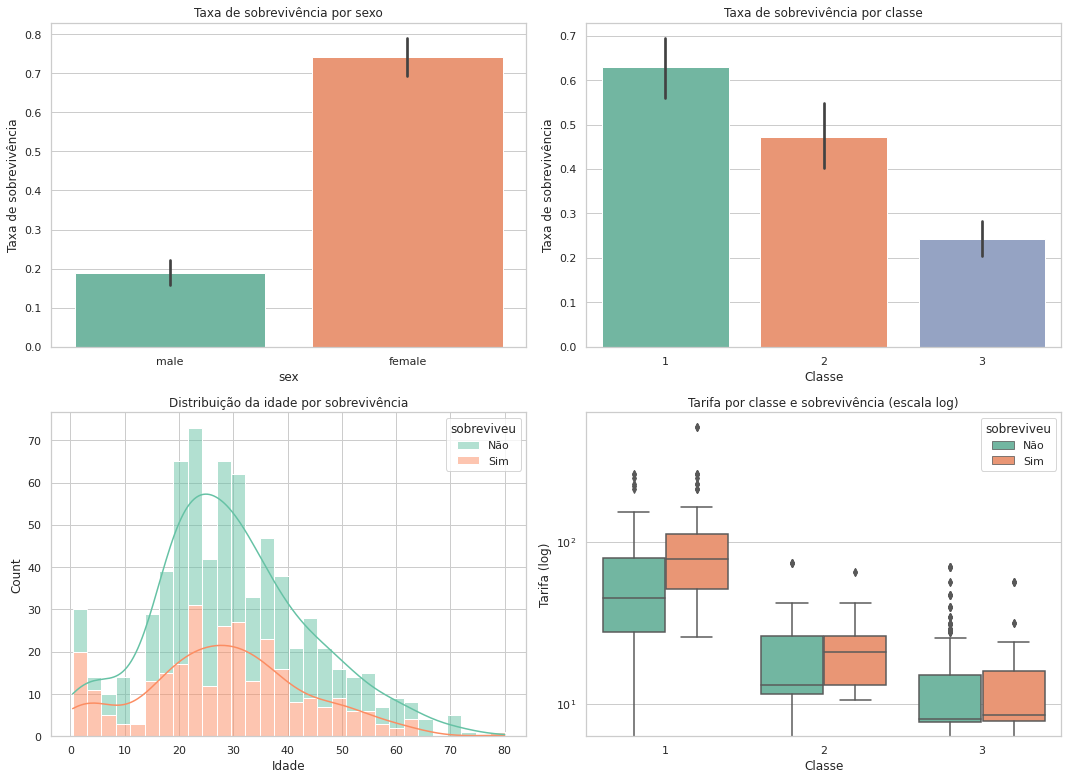

In [7]:
plot_df = df_raw.assign(sobreviveu=df_raw['survived'].map({0: 'Não', 1: 'Sim'}))

fig, axes = plt.subplots(2, 2, figsize=(15, 11))

sns.barplot(data=plot_df, x='sex', y='survived', ax=axes[0, 0])
axes[0, 0].set_title('Taxa de sobrevivência por sexo')
axes[0, 0].set_ylabel('Taxa de sobrevivência')

sns.barplot(data=plot_df, x='pclass', y='survived', ax=axes[0, 1])
axes[0, 1].set_title('Taxa de sobrevivência por classe')
axes[0, 1].set_xlabel('Classe')
axes[0, 1].set_ylabel('Taxa de sobrevivência')

sns.histplot(data=plot_df, x='age', hue='sobreviveu', bins=30, kde=True,
             multiple='stack', ax=axes[1, 0])
axes[1, 0].set_title('Distribuição da idade por sobrevivência')
axes[1, 0].set_xlabel('Idade')

sns.boxplot(data=plot_df, x='pclass', y='fare', hue='sobreviveu', ax=axes[1, 1])
axes[1, 1].set_yscale('log')
axes[1, 1].set_title('Tarifa por classe e sobrevivência (escala log)')
axes[1, 1].set_xlabel('Classe')
axes[1, 1].set_ylabel('Tarifa (log)')

plt.tight_layout()
plt.show()

### 1.4 Correlações entre variáveis

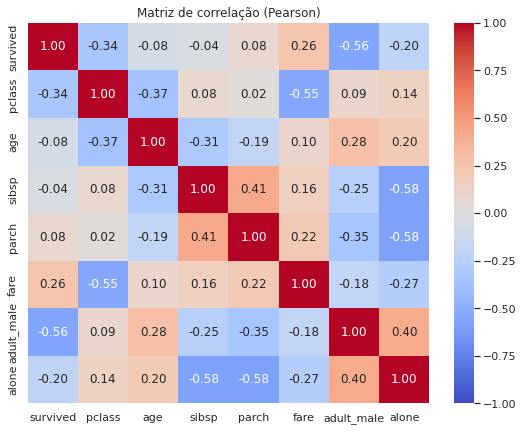

Correlação de cada variável com a sobrevivência:
adult_male   -0.56
pclass       -0.34
alone        -0.20
age          -0.08
sibsp        -0.04
parch         0.08
fare          0.26


In [8]:
corr_df = df_raw[['survived', 'pclass', 'age', 'sibsp', 'parch', 'fare', 'adult_male', 'alone']].astype(float)
corr = corr_df.corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Matriz de correlação (Pearson)')
plt.show()

print('Correlação de cada variável com a sobrevivência:')
print(corr['survived'].drop('survived').sort_values().to_string())

### 1.5 Padrões cruzados: sexo × classe

Taxa de sobrevivência (sexo × classe):


pclass,1,2,3
sex,,,
female,0.97,0.92,0.50
male,0.37,0.16,0.14


Número de passageiros:


pclass,1,2,3
sex,,,
female,94,76,144
male,122,108,347


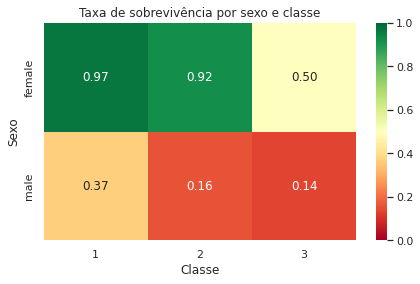

In [9]:
pivot_taxa = df_raw.pivot_table(index='sex', columns='pclass', values='survived', aggfunc='mean')
pivot_n = df_raw.pivot_table(index='sex', columns='pclass', values='survived', aggfunc='count')

print('Taxa de sobrevivência (sexo × classe):')
display(pivot_taxa)
print('Número de passageiros:')
display(pivot_n)

plt.figure(figsize=(7, 4))
sns.heatmap(pivot_taxa, annot=True, fmt='.2f', cmap='RdYlGn', vmin=0, vmax=1)
plt.title('Taxa de sobrevivência por sexo e classe')
plt.xlabel('Classe')
plt.ylabel('Sexo')
plt.show()

## 2. Tratamento e limpeza
### 2.1 Valores em falta

In [10]:
missing = pd.DataFrame({
    'n_nulos': df_raw.isna().sum(),
    '%_nulos': (df_raw.isna().mean() * 100).round(2)
})
missing = missing[missing['n_nulos'] > 0].sort_values('n_nulos', ascending=False)
missing

,n_nulos,%_nulos
deck,688,77.22
age,177,19.87
embarked,2,0.22
embark_town,2,0.22


### 2.2 Registos duplicados e inconsistências

O dataset **não tem identificador de passageiro**, por isso dois registos iguais em todos os atributos não podem ser confirmados como o mesmo passageiro. Mesmo assim, são tratados como redundantes, porque a instrução pede a identificação desses registos. Também se verificam inconsistências lógicas entre colunas.

In [11]:
dup_mask = df_raw.duplicated(keep=False)
print(f'Registos duplicados (todas as cópias): {dup_mask.sum()}')
print(f'Cópias redundantes (a remover, excluindo a 1ª ocorrência): {df_raw.duplicated().sum()}')
print(f'Taxa de sobrevivência dos registos duplicados: {df_raw[dup_mask]["survived"].mean():.2%}')
print(f'Taxa de sobrevivência dos restantes registos:  {df_raw[~dup_mask]["survived"].mean():.2%}')
print()

checks = pd.Series({
    'alone não coincide com (sibsp + parch == 0)': int((df_raw['alone'] != ((df_raw['sibsp'] + df_raw['parch']) == 0)).sum()),
    'alive não coincide com survived': int(((df_raw['alive'] == 'yes').astype(int) != df_raw['survived']).sum()),
    'adult_male não coincide com who == "man"': int(((df_raw['who'] == 'man') != df_raw['adult_male']).sum()),
    'class não coincide com pclass': int((df_raw['class'].astype(str).map({'First': 1, 'Second': 2, 'Third': 3}) != df_raw['pclass']).sum()),
    'embarked não coincide com embark_town': int(((df_raw['embarked'].map({'C': 'Cherbourg', 'Q': 'Queenstown', 'S': 'Southampton'}) != df_raw['embark_town']) & df_raw['embarked'].notna()).sum()),
    'idade fora do intervalo 0-100': int(((df_raw['age'] < 0) | (df_raw['age'] > 100)).sum()),
    'tarifa igual a 0 (bilhetes gratuitos, mantidos)': int((df_raw['fare'] == 0).sum()),
})
checks.rename('nº de casos').to_frame()

Registos duplicados (todas as cópias): 160
Cópias redundantes (a remover, excluindo a 1ª ocorrência): 107
Taxa de sobrevivência dos registos duplicados: 19.38%
Taxa de sobrevivência dos restantes registos:  42.54%



,nº de casos
alone não coincide com (sibsp + parch == 0),0
alive não coincide com survived,0
"adult_male não coincide com who == ""man""",0
class não coincide com pclass,0
embarked não coincide com embark_town,0
idade fora do intervalo 0-100,0
"tarifa igual a 0 (bilhetes gratuitos, mantidos)",15


### 2.3 Ações de limpeza

Decisões tomadas:
- **Duplicados**: removem-se as cópias redundantes (mantém-se a 1ª ocorrência).
- **Idade (≈20% em falta)**: imputação pela mediana, calculada por grupo de sexo × classe. Assim a idade reflete o perfil de cada grupo, e não a mediana global.
- **Embarque (2 em falta)**: imputação pela moda (`S`).
- **Deck (≈77% em falta)**: coluna removida, porque a imputação introduziria mais ruído do que informação.
- **Colunas redundantes**: `class` (duplica `pclass`), `alive` (duplica `survived`) e `embark_town` (duplica `embarked`) são removidas.
- **Tarifas a 0**: mantêm-se, porque são casos plausíveis (bilhetes de cortesia ou de tripulação).

In [12]:
df = df_raw.copy()
log_acoes = []

# 1. Duplicados
n_antes = len(df)
df = df.drop_duplicates().reset_index(drop=True)
log_acoes.append(('Duplicados', 'Removidas cópias redundantes (1ª ocorrência mantida)', n_antes - len(df)))

# 2. Idade: mediana por sexo × classe
nulos_idade = int(df['age'].isna().sum())
mediana_grupo = df.groupby(['sex', 'pclass'])['age'].transform('median')
df['age'] = df['age'].fillna(mediana_grupo)
log_acoes.append(('age', 'Imputação pela mediana por sexo × classe', nulos_idade))

# 3. Embarque: moda
nulos_emb = int(df['embarked'].isna().sum())
df['embarked'] = df['embarked'].fillna(df['embarked'].mode()[0])
log_acoes.append(('embarked', 'Imputação pela moda', nulos_emb))

# 4. Deck: demasiados nulos
nulos_deck = int(df['deck'].isna().sum())
df = df.drop(columns='deck')
log_acoes.append(('deck', 'Coluna removida (≈77% em falta)', nulos_deck))

# 5. Colunas redundantes
for col, motivo in [('class', 'Duplica pclass'),
                    ('alive', 'Duplica survived'),
                    ('embark_town', 'Duplica embarked')]:
    df = df.drop(columns=col)
    log_acoes.append((col, f'Coluna removida: {motivo}', 0))

resumo_limpeza = pd.DataFrame(log_acoes, columns=['coluna', 'ação', 'registos/valores afetados'])
print(f'Registos: {n_antes} -> {len(df)} | Colunas: {df_raw.shape[1]} -> {df.shape[1]}')
print(f'Valores em falta restantes: {int(df.isna().sum().sum())}')
print()
display(resumo_limpeza)

Registos: 891 -> 784 | Colunas: 15 -> 11
Valores em falta restantes: 0



,coluna,ação,registos/valores afetados
0,Duplicados,Removidas cópias redundantes (1ª ocorrência ma...,107
1,age,Imputação pela mediana por sexo × classe,106
2,embarked,Imputação pela moda,2
3,deck,Coluna removida (≈77% em falta),582
4,class,Coluna removida: Duplica pclass,0
5,alive,Coluna removida: Duplica survived,0
6,embark_town,Coluna removida: Duplica embarked,0


In [13]:
print(f"Taxa de sobrevivência antes da limpeza: {df_raw['survived'].mean():.2%}")
print(f"Taxa de sobrevivência depois da limpeza:  {df['survived'].mean():.2%}")
print()
print('Taxa de sobrevivência por sexo e classe (após limpeza):')
display(df.pivot_table(index='sex', columns='pclass', values='survived', aggfunc='mean'))

Taxa de sobrevivência antes da limpeza: 38.38%
Taxa de sobrevivência depois da limpeza:  41.20%

Taxa de sobrevivência por sexo e classe (após limpeza):


pclass,1,2,3
sex,,,
female,0.97,0.92,0.47
male,0.37,0.18,0.16


## 3. Feature Engineering

### 3.1 Agregação de laços familiares e atributos derivados

- `tamanho_familia` = irmãos/cônjuges (`sibsp`) + pais/filhos (`parch`) + o próprio passageiro.
- `viaja_sozinho` (binário): 1 se o passageiro não tem família a bordo.
- `tarifa_por_pessoa`: tarifa dividida pelo tamanho da família, para corrigir o efeito dos bilhetes partilhados.
- `grupo_familia`: categoria com os níveis Sozinho, Pequena (2-4) e Grande (5+).

In [14]:
fe = df.copy()

fe['tamanho_familia'] = fe['sibsp'] + fe['parch'] + 1
fe['viaja_sozinho'] = (fe['tamanho_familia'] == 1).astype(int)
fe['tarifa_por_pessoa'] = fe['fare'] / fe['tamanho_familia']
fe['grupo_familia'] = pd.cut(fe['tamanho_familia'], bins=[0, 1, 4, 20],
                             labels=['Sozinho', 'Pequena (2-4)', 'Grande (5+)'])

print(fe['tamanho_familia'].value_counts().sort_index().to_string())
print()
print(fe[['tamanho_familia', 'viaja_sozinho', 'tarifa_por_pessoa', 'grupo_familia']].head())

1     446
2     154
3     101
4      28
5      13
6      22
7      12
8       6
11      2

   tamanho_familia  viaja_sozinho  tarifa_por_pessoa  grupo_familia
0                2              0               3.62  Pequena (2-4)
1                2              0              35.64  Pequena (2-4)
2                1              1               7.92        Sozinho
3                2              0              26.55  Pequena (2-4)
4                1              1               8.05        Sozinho


### 3.2 Binning etário

Os grupos etários são definidos com base em faixas de desenvolvimento e de papel social, e não em quantis, para ficarem interpretáveis.

In [15]:
fe['grupo_etario'] = pd.cut(
    fe['age'],
    bins=[0, 12, 18, 35, 60, 100],
    labels=['Criança (0-12)', 'Adolescente (13-18)', 'Jovem adulto (19-35)',
            'Adulto (36-60)', 'Idoso (61+)'],
    include_lowest=True
)
print(fe['grupo_etario'].value_counts().sort_index().to_string())

Criança (0-12)           68
Adolescente (13-18)      67
Jovem adulto (19-35)    415
Adulto (36-60)          212
Idoso (61+)              22


### 3.3 Codificação binária e one-hot

- `sexo_masculino` (0/1) e `menor_18` (0/1): codificação binária direta.
- `embarked` e `pclass`: codificação one-hot com `drop_first=True`, para evitar multicolinearidade na modelação.
- `grupo_familia` e `grupo_etario`: one-hot, com a primeira categoria como referência.

In [16]:
fe['sexo_masculino'] = (fe['sex'] == 'male').astype(int)
fe['menor_18'] = (fe['age'] < 18).astype(int)

dummies = pd.get_dummies(
    fe[['embarked', 'pclass', 'grupo_familia', 'grupo_etario']],
    columns=['embarked', 'pclass', 'grupo_familia', 'grupo_etario'],
    prefix=['embarked', 'pclass', 'familia', 'etario'],
    drop_first=True, dtype=int
)

colunas_base = ['survived', 'sexo_masculino', 'menor_18', 'age', 'fare',
                'tamanho_familia', 'viaja_sozinho', 'tarifa_por_pessoa']
df_modelo = pd.concat([fe[colunas_base], dummies], axis=1)

print(f'Dataset preparado: {df_modelo.shape[0]} linhas x {df_modelo.shape[1]} colunas')
print(f'Valores em falta: {int(df_modelo.isna().sum().sum())}')
print()
print(df_modelo.dtypes.to_string())
print()
df_modelo.head()

Dataset preparado: 784 linhas x 18 colunas
Valores em falta: 0

survived                         int64
sexo_masculino                   int64
menor_18                         int64
age                            float64
fare                           float64
tamanho_familia                  int64
viaja_sozinho                    int64
tarifa_por_pessoa              float64
embarked_Q                       int64
embarked_S                       int64
pclass_2                         int64
pclass_3                         int64
familia_Pequena (2-4)            int64
familia_Grande (5+)              int64
etario_Adolescente (13-18)       int64
etario_Jovem adulto (19-35)      int64
etario_Adulto (36-60)            int64
etario_Idoso (61+)               int64



,survived,sexo_masculino,menor_18,age,fare,tamanho_familia,viaja_sozinho,tarifa_por_pessoa,embarked_Q,embarked_S,pclass_2,pclass_3,familia_Pequena (2-4),familia_Grande (5+),etario_Adolescente (13-18),etario_Jovem adulto (19-35),etario_Adulto (36-60),etario_Idoso (61+)
0,0,1,0,22.00,7.25,2,0,3.62,0,1,0,1,1,0,0,1,0,0
1,1,0,0,38.00,71.28,2,0,35.64,0,0,0,0,1,0,0,0,1,0
2,1,0,0,26.00,7.92,1,1,7.92,0,1,0,1,0,0,0,1,0,0
3,1,0,0,35.00,53.10,2,0,26.55,0,1,0,0,1,0,0,1,0,0
4,0,1,0,35.00,8.05,1,1,8.05,0,1,0,1,0,0,0,1,0,0


### 3.4 Validação: as novas variáveis separam a sobrevivência?

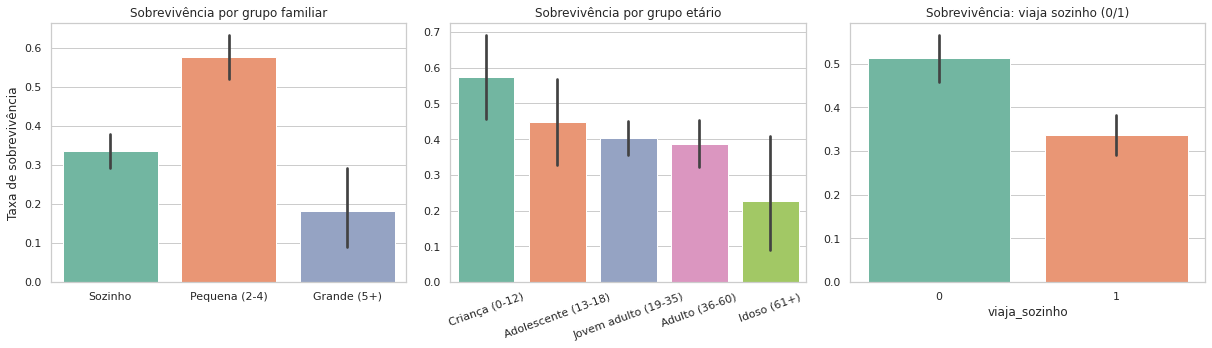

Correlação das novas variáveis com a sobrevivência:
sexo_masculino                -0.52
pclass_3                      -0.33
viaja_sozinho                 -0.18
familia_Grande (5+)           -0.13
embarked_S                    -0.13
age                           -0.08
etario_Idoso (61+)            -0.06
embarked_Q                    -0.04
etario_Adulto (36-60)         -0.03
etario_Jovem adulto (19-35)   -0.02
tamanho_familia                0.01
etario_Adolescente (13-18)     0.02
pclass_2                       0.10
menor_18                       0.11
tarifa_por_pessoa              0.21
fare                           0.25
familia_Pequena (2-4)          0.25


In [17]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

sns.barplot(data=fe, x='grupo_familia', y='survived', ax=axes[0])
axes[0].set_title('Sobrevivência por grupo familiar')
axes[0].set_xlabel('')
axes[0].set_ylabel('Taxa de sobrevivência')

sns.barplot(data=fe, x='grupo_etario', y='survived', ax=axes[1])
axes[1].set_title('Sobrevivência por grupo etário')
axes[1].set_xlabel('')
axes[1].set_ylabel('')
axes[1].tick_params(axis='x', rotation=20)

sns.barplot(data=fe, x='viaja_sozinho', y='survived', ax=axes[2])
axes[2].set_title('Sobrevivência: viaja sozinho (0/1)')
axes[2].set_xlabel('viaja_sozinho')
axes[2].set_ylabel('')

plt.tight_layout()
plt.show()

print('Correlação das novas variáveis com a sobrevivência:')
print(df_modelo.corr()['survived'].drop('survived').sort_values().to_string())